# 02 · RFM customer segmentation

Scores each of the 267,708 sampled customers on Recency, Frequency and Monetary value, then groups them into six segments.

- **Snapshot date:** 2020-09-23, the day after the last transaction.
- **Frequency** counts distinct purchase dates, not line items.
- **Monetary** is the sum of `price`. Price is anonymized and scaled by H&M, so this is a relative spend score, not currency.
- **Scoring:** recency and monetary use quintiles (1 to 5). Frequency uses fixed bins (1, 2, 3, 4 to 5, 6+ purchase days), because about 49% of customers bought on exactly one day and quintiles can't split a tie that large. Every raw value maps to exactly one score.

All three measures come from a three-month window. "Lost" here means a low recency score and one or two purchase days within that window. It does not mean the customer never came back after September 2020.

**Methodology change.** An earlier version ranked frequency with `method='first'`, which split tied values by row order. That handed about 24,600 one-time buyers an F score of 3 at random and put about 14,000 of them in At Risk. The scoring below fixes that. Lost was the largest segment under both versions.

In [1]:
from dotenv import load_dotenv
import psycopg2
import os

load_dotenv(override=True)
conn = psycopg2.connect(os.getenv("SUPABASE_CONNECTION_STRING"))
cur = conn.cursor()
print("Connected successfully")

Connected successfully


In [2]:
cur.execute("""
    SELECT
        customer_id,
        (DATE '2020-09-23' - MAX(t_dat)) AS recency_days,
        COUNT(DISTINCT t_dat) AS frequency,
        SUM(price) AS monetary
    FROM transactions
    GROUP BY customer_id;
""")
rfm_raw = cur.fetchall()
print(f"Computed RFM for {len(rfm_raw)} customers")
print(rfm_raw[:5])  # peek at the first 5 rows

Computed RFM for 267708 customers
[('00000dbacae5abe5e23885899a1fa44253a17956c6d1c3d25f88aa139fdfc657', 18, 1, Decimal('0.0508305084745762')), ('00006413d8573cd20ed7128e53b7b13819fe5cfc2d801fe7fc0f26dd8d65a85a', 42, 1, Decimal('0.1287457627118641')), ('0000757967448a6cb83efb3ea7a3fb9d418ac7adf2379d8cd0c725276a467a2a', 9, 1, Decimal('0.0762372881355931')), ('00009d946eec3ea54add5ba56d5210ea898def4b46c68570cf0096d962cacc75', 24, 3, Decimal('0.8098305084745749')), ('0000f1c71aafe5963c3d195cf273f7bfd50bbf17761c9199e53dbb81641becd7', 55, 2, Decimal('0.3540338983050841'))]


In [3]:
import pandas as pd

rfm_df = pd.DataFrame(rfm_raw, columns=['customer_id', 'recency', 'frequency', 'monetary'])
rfm_df['monetary'] = rfm_df['monetary'].astype(float)

print(rfm_df.describe())

             recency      frequency       monetary
count  267708.000000  267708.000000  267708.000000
mean       39.610482       2.276447       0.201052
std        27.623653       2.174891       0.275606
min         1.000000       1.000000       0.000780
25%        15.000000       1.000000       0.055881
50%        35.000000       2.000000       0.115983
75%        62.000000       3.000000       0.238746
max        93.000000      68.000000      13.119119


In [4]:
# Equal raw values must get equal scores. An earlier version ranked with
# method='first', which split tied values by row order. That matters here:
# about half of all customers bought on exactly one day, so their F scores
# (and their segments) depended on row order rather than behaviour.

# Recency: quintiles on the raw value, so customers on the same day share a score.
rfm_df['r_score'] = 5 - pd.qcut(rfm_df['recency'], 5, labels=False, duplicates='drop')

# Frequency: fixed bins on purchase days. Values are small integers with heavy
# ties (1 day: ~49%), so quintiles cannot split them cleanly.
rfm_df['f_score'] = pd.cut(
    rfm_df['frequency'],
    bins=[0, 1, 2, 3, 5, float('inf')],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: near-continuous, so quintiles on rank with ties averaged.
rfm_df['m_score'] = pd.qcut(rfm_df['monetary'].rank(method='average'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Check: every raw value maps to exactly one score
assert rfm_df.groupby('recency')['r_score'].nunique().max() == 1
assert rfm_df.groupby('frequency')['f_score'].nunique().max() == 1

print(rfm_df.groupby('r_score')['recency'].agg(['min', 'max', 'count']))
print()
print(rfm_df.groupby('f_score')['frequency'].agg(['min', 'max', 'count']))


         min  max  count
r_score                 
1         70   93  51524
2         47   69  53472
3         27   46  53827
4         13   26  53608
5          1   12  55277

         min  max   count
f_score                  
1          1    1  131712
2          2    2   59925
3          3    3   31715
4          4    5   27513
5          6   68   16843


Segment rules are applied in order, so a customer lands in the first segment they match. Anyone matching none of the named rules falls into **Needs Attention**.

In [5]:
def rfm_segment(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif f >= 4 and m >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'New / Promising'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r <= 2 and f <= 2:
        return 'Lost'
    else:
        return 'Needs Attention'

rfm_df['segment'] = rfm_df.apply(rfm_segment, axis=1)

segment_counts = rfm_df['segment'].value_counts()
print(segment_counts)
print()
print("Percentage of total:")
print((segment_counts / len(rfm_df) * 100).round(1))

segment
Lost               94796
Needs Attention    63434
New / Promising    58695
Champions          30801
Loyal Customers    13115
At Risk             6867
Name: count, dtype: int64

Percentage of total:
segment
Lost               35.4
Needs Attention    23.7
New / Promising    21.9
Champions          11.5
Loyal Customers     4.9
At Risk             2.6
Name: count, dtype: float64


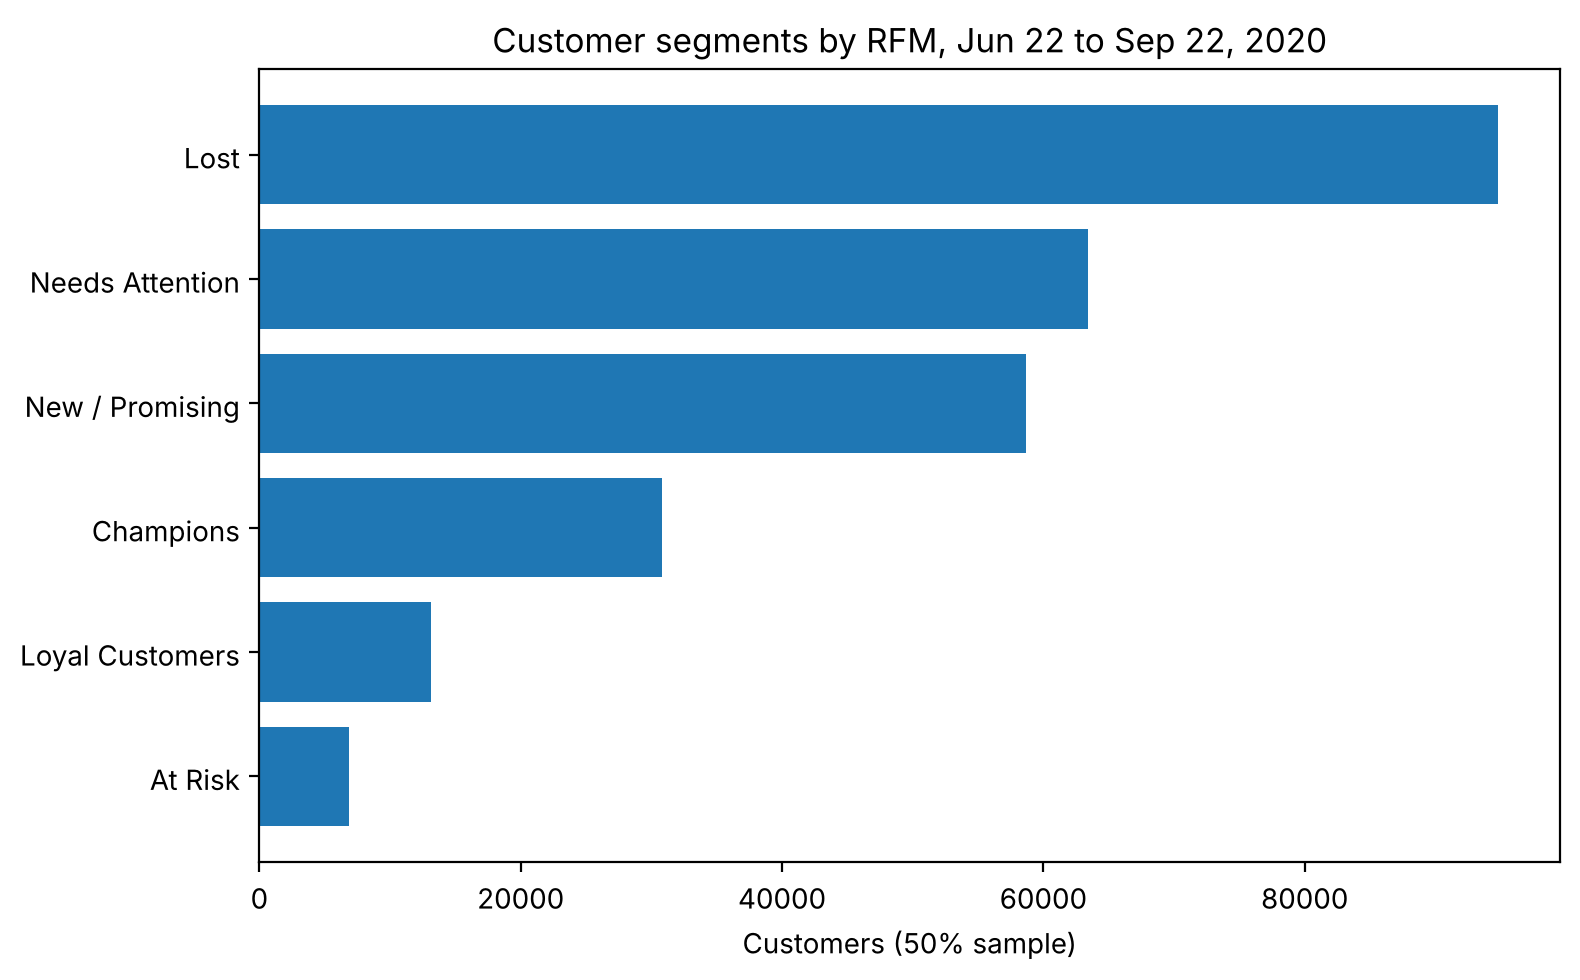

In [6]:
import matplotlib.pyplot as plt

segment_counts_sorted = segment_counts.sort_values(ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(segment_counts_sorted.index, segment_counts_sorted.values)
plt.xlabel('Customers (50% sample)')
plt.title('Customer segments by RFM, Jun 22 to Sep 22, 2020')
plt.tight_layout()
plt.savefig('../outputs/figures/rfm_segments.png', dpi=150)
plt.show()


**Finding:** Lost is the largest segment: 94,796 customers (35.4%) who bought on only one or two days and hadn't bought in the final 47+ days of the window. Champions and Loyal Customers together are 16.4%. Most of this customer base shops occasionally, and a third of it had already lapsed within three months.

In [7]:
rfm_df.to_csv('../outputs/summary_tables/rfm_segments.csv', index=False)
print(f"Saved {len(rfm_df)} customer RFM records")

Saved 267708 customer RFM records
